NAME - DEVADHARSHINI M

PROJECT NAME - SALES PREDICTION USING PYTHON

In [6]:


# import libraries
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Visualization theme
sns.set_theme(style="whitegrid")

# Light blue color palette
BLUE = "#87CEEB"
DARK_BLUE = "#4682B4"
LIGHT_BLUE = "#D6ECFA"

print("All libraries imported successfully!")


All libraries imported successfully!


In [7]:

#load dataset

DATA_URL = "https://raw.githubusercontent.com/devadharshinimurugan06-commits/CODSOFT_TASKS_Devadharshini/main/Task3_Sales_Prediction/CodSoft_Sales_Prediction_Dataset.xlsx"

# Load Excel dataset from GitHub
df = pd.read_excel(DATA_URL, engine="openpyxl")

print("Dataset Loaded Successfully!")

print("\nDataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Records:")
display(df.head())

print("\nDataset Information:")
df.info()


Dataset Loaded Successfully!

Dataset Shape: (200, 4)

Column Names:
['TV', 'Radio', 'Newspaper', 'Sales']

First 5 Records:


,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


In [8]:

# DATASET QUALITY CHECK


print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
display(df.dtypes.to_frame("Data Type"))

print("\nMissing Values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate Records:", df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe(include="all").T)


Dataset Shape: (200, 4)

Column Names:
['TV', 'Radio', 'Newspaper', 'Sales']

Data Types:


,Data Type
TV,float64
Radio,float64
Newspaper,float64
Sales,float64



Missing Values:


,Missing Values
TV,0
Radio,0
Newspaper,0
Sales,0



Duplicate Records: 0

Statistical Summary:


,count,mean,std,min,25%,50%,75%,max
TV,200.0,147.0425,85.854236,0.7,74.375,149.75,218.825,296.4
Radio,200.0,23.2640,14.846809,0.0,9.975,22.90,36.525,49.6
Newspaper,200.0,30.5540,21.778621,0.3,12.750,25.75,45.100,114.0
Sales,200.0,14.0225,5.217457,1.6,10.375,12.90,17.400,27.0


In [9]:

# CELL 4 - DATA CLEANING


# Create a clean copy
df_clean = df.copy()

# Remove duplicate records (if any)
df_clean = df_clean.drop_duplicates()

# Check missing values
print("Missing Values:")
print(df_clean.isnull().sum())

# Check duplicates
print("\nDuplicate Records:", df_clean.duplicated().sum())

# Final dataset shape
print("\nOriginal Dataset Shape:", df.shape)
print("Cleaned Dataset Shape:", df_clean.shape)

print("\nData Cleaning Completed Successfully!")

display(df_clean.head())


Missing Values:
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

Duplicate Records: 0

Original Dataset Shape: (200, 4)
Cleaned Dataset Shape: (200, 4)

Data Cleaning Completed Successfully!


,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


In [10]:
print("Missing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nStatistical Summary:")
display(df.describe())

Missing values:
 TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

Duplicate rows: 0

Statistical Summary:


,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14.022500
std,85.854236,14.846809,21.778621,5.217457
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,10.375000
50%,149.750000,22.900000,25.750000,12.900000
75%,218.825000,36.525000,45.100000,17.400000
max,296.400000,49.600000,114.000000,27.000000


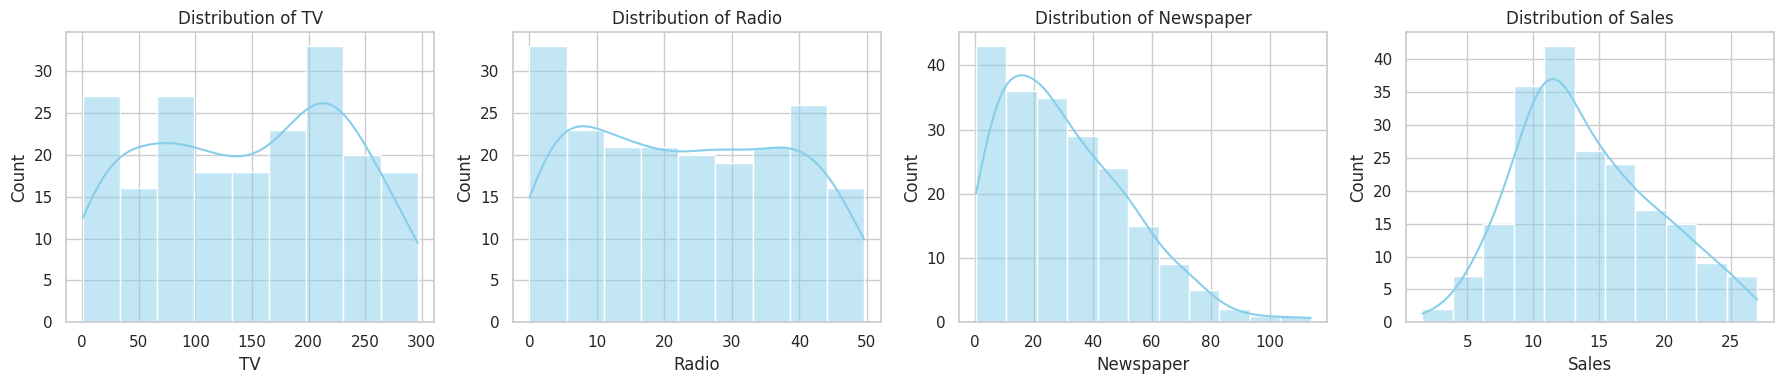

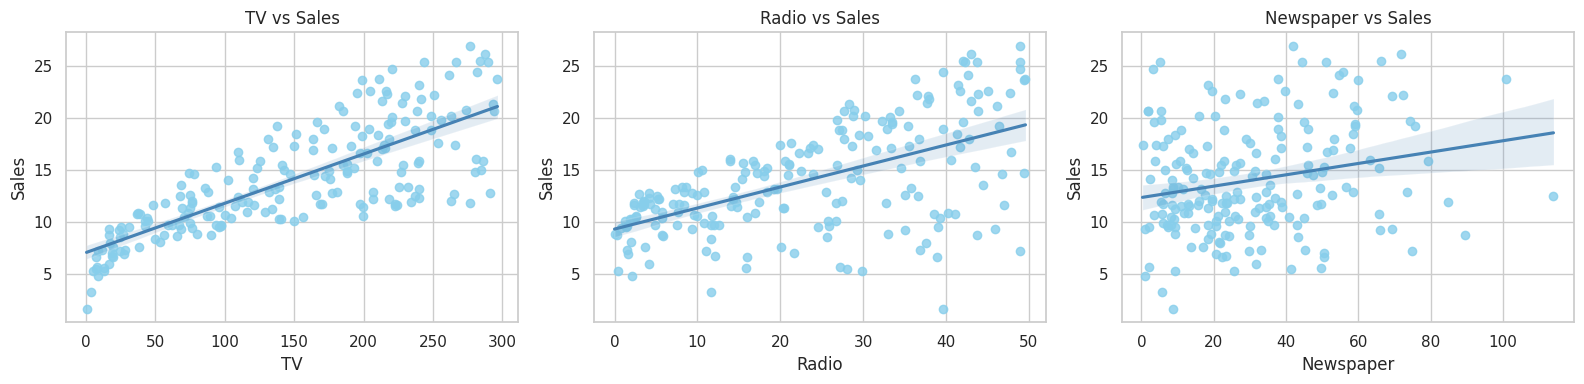

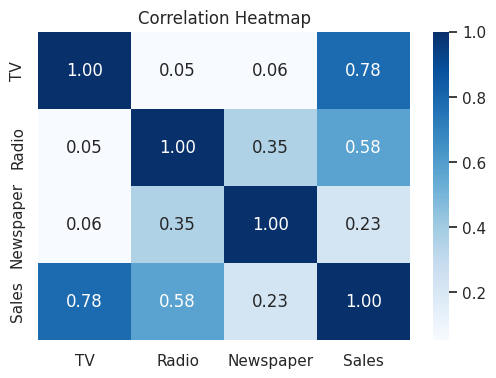

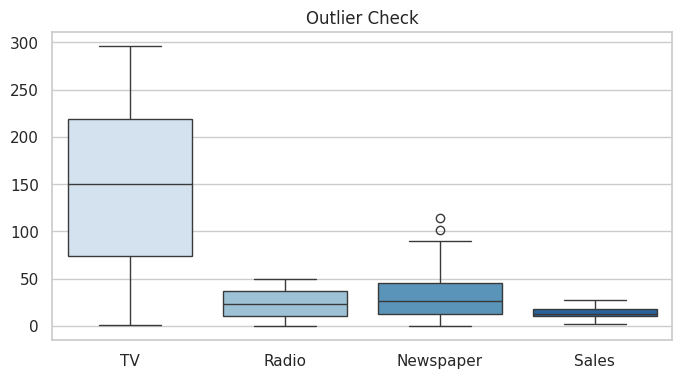

In [11]:
# Distributions
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, df.columns):
    sns.histplot(df[col], kde=True, color=BLUE, ax=ax)
    ax.set_title(f"Distribution of {col}")
plt.tight_layout()
plt.show()

# Relationship of each ad channel with Sales
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["TV", "Radio", "Newspaper"]):
    sns.regplot(x=df[col], y=df["Sales"], ax=ax,
                scatter_kws={"color": BLUE}, line_kws={"color": DARK_BLUE})
    ax.set_title(f"{col} vs Sales")
plt.tight_layout()
plt.show()

# Correlation heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(df.corr(), annot=True, cmap="Blues", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

# Boxplots to spot outliers
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, palette="Blues")
plt.title("Outlier Check")
plt.show()

In [12]:
#split

X = df[["TV", "Radio", "Newspaper"]]
y = df["Sales"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (160, 3) Test: (40, 3)


In [13]:
from sklearn.ensemble import RandomForestRegressor

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42),
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred),
    })

results_df = pd.DataFrame(results)
display(results_df)

,Model,MAE,RMSE,R2
0,Linear Regression,1.460757,1.781600,0.899438
1,Random Forest,0.628713,0.757235,0.981833


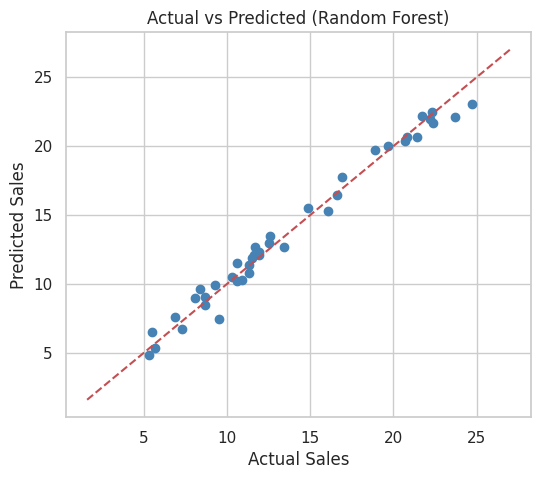

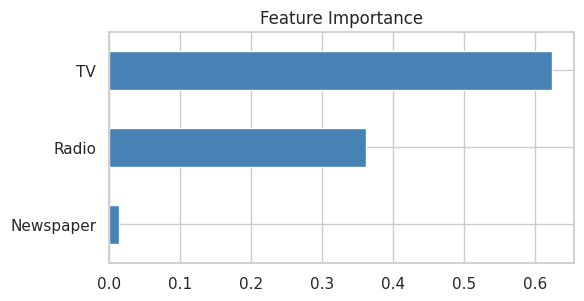

In [14]:
best_model = models["Random Forest"]
y_pred = best_model.predict(X_test)

# Actual vs Predicted
plt.figure(figsize=(6, 5))
plt.scatter(y_test, y_pred, color=DARK_BLUE)
plt.plot([y.min(), y.max()], [y.min(), y.max()], "r--")
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted (Random Forest)")
plt.show()

# Feature importance
importance = pd.Series(best_model.feature_importances_, index=X.columns).sort_values()
importance.plot(kind="barh", color=DARK_BLUE, figsize=(6, 3),
                title="Feature Importance")
plt.show()

In [15]:
#Business insights
lr = models["Linear Regression"]
coef = pd.Series(lr.coef_, index=X.columns)
print("Sales change per 1 unit of ad spend:\n")
print(coef)

Sales change per 1 unit of ad spend:

TV           0.044730
Radio        0.189195
Newspaper    0.002761
dtype: float64


In [17]:
#model save
import joblib
joblib.dump(best_model, "sales_model.pkl")

from google.colab import files
files.download("sales_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>